<a href="https://colab.research.google.com/github/dkundra374-sketch/Chest-X-ray-Pneumonia-Binary-Detection/blob/main/Chest_X_ray(Pneumonia).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/

In [2]:
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [00:17<00:00, 142MB/s]



In [3]:
import zipfile
zip_ref = zipfile.ZipFile('/content/chest-xray-pneumonia.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [4]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense,Conv2D,MaxPooling2D,Flatten,BatchNormalization,Dropout,GlobalAveragePooling2D

In [5]:
#generators - divide whole data to batches.then one batch is load in ram at one time ,once it work is done it is removed and next batch comes to work
train_ds=keras.utils.image_dataset_from_directory(
    directory='/content/chest_xray/train',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(256,256),
    seed=42
)
test_ds=keras.utils.image_dataset_from_directory(
    directory='/content/chest_xray/test',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(256,256),
    shuffle=False
)
validation_ds=keras.utils.image_dataset_from_directory(
    directory='/content/chest_xray/val',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(256,256),
    seed=42
)

Found 5216 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Found 16 files belonging to 2 classes.


In [6]:
#NORMALIZE: becaue stored 0-255 form we need it to convert it to 0-1
def process(image,label):
  image=tf.cast(image/255.0,tf.float32)
  return image,label

train_ds=train_ds.map(process).prefetch(tf.data.AUTOTUNE)       #added prefetch
validation_ds=validation_ds.map(process).prefetch(tf.data.AUTOTUNE)
test_ds=test_ds.map(process).prefetch(tf.data.AUTOTUNE)         # test set normalized

In [22]:
DROPOUT = 0.2
# create CNN model
model=Sequential()
model.add(tf.keras.layers.Input(shape=(256,256,3)))

model.add(Conv2D(64,kernel_size=(3,3),padding='same',activation='relu',input_shape=(256,256,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),padding='same'))


model.add(Conv2D(64,kernel_size=(3,3),padding='same',activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),padding='same'))

model.add(Conv2D(128,kernel_size=(3,3),padding='same',activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),padding='same'))


model.add(GlobalAveragePooling2D())   # CHANGED: was Flatten() (16.8M params -> far fewer, less overfitting)
#fully connected layer(3 layers)
model.add(Dense(256,activation='relu'))
model.add(Dropout(DROPOUT))
model.add(Dense(64,activation='relu'))
model.add(Dropout(DROPOUT))
model.add(Dense(1,activation='sigmoid'))#output


In [23]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_16 (Conv2D)              │ (None, 256, 256, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 256, 256, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 128, 128, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 163,137 (637.25 KB)

 Trainable params: 162,625 (635.25 KB)

 Non-trainable params: 512 (2.00 KB)

In [24]:
#compile and execute
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-2),   # CHANGED: lower learning rate (default 1e-3 was unstable)
    loss='binary_crossentropy',
    metrics=['accuracy',
             keras.metrics.Recall(name='recall'),
             keras.metrics.AUC(name='auc')]
)

In [25]:
class_weight = {0: 1.94, 1: 0.67}   # NORMAL is the minority class (1341 vs 3875)

callbacks = [                        # NEW
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-6),
]

history=model.fit(train_ds,
                  epochs=40,                        # CHANGED: 10 -> 40 (early stopping ends it sooner)
                  validation_data=validation_ds,
                  class_weight=class_weight,
                  callbacks=callbacks)

Epoch 1/40
163/163 ━━━━━━━━━━━━━━━━━━━━ 48s 190ms/step - accuracy: 0.7337 - auc: 0.8382 - loss: 0.5254 - recall: 0.6945 - val_accuracy: 0.5000 - val_auc: 0.5859 - val_loss: 2.3727 - val_recall: 1.0000 - learning_rate: 0.0300
Epoch 2/40
163/163 ━━━━━━━━━━━━━━━━━━━━ 66s 180ms/step - accuracy: 0.6392 - auc: 0.7776 - loss: 0.5556 - recall: 0.5363 - val_accuracy: 0.5625 - val_auc: 0.6641 - val_loss: 2.0010 - val_recall: 1.0000 - learning_rate: 0.0300
Epoch 3/40
163/163 ━━━━━━━━━━━━━━━━━━━━ 30s 183ms/step - accuracy: 0.6191 - auc: 0.7571 - loss: 0.5712 - recall: 0.5045 - val_accuracy: 0.5000 - val_auc: 0.5000 - val_loss: 4.3804 - val_recall: 1.0000 - learning_rate: 0.0300
Epoch 4/40
163/163 ━━━━━━━━━━━━━━━━━━━━ 40s 180ms/step - accuracy: 0.7485 - auc: 0.8574 - loss: 0.4511 - recall: 0.6800 - val_accuracy: 0.5625 - val_auc: 0.6094 - val_loss: 0.7574 - val_recall: 0.6250 - learning_rate: 0.0300
Epoch 5/40
163/163 ━━━━━━━━━━━━━━━━━━━━ 30s 181ms/step - accuracy: 0.8290 - auc: 0.9093 - loss: 0.38

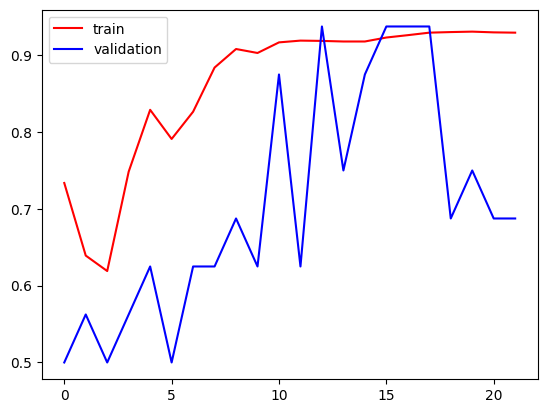

In [26]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

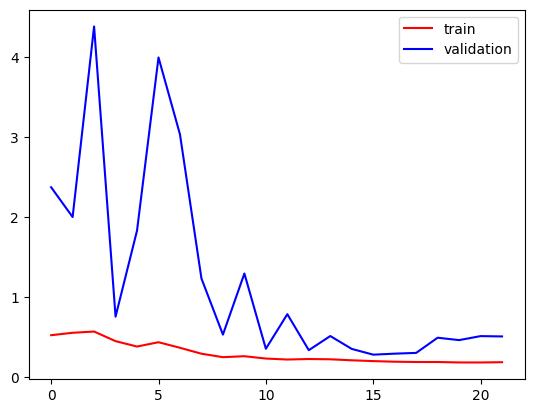

In [28]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

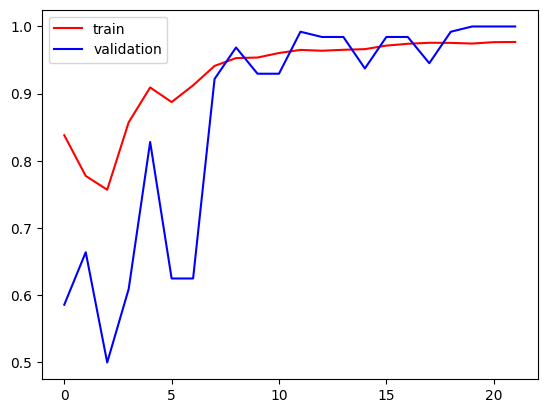

In [29]:
plt.plot(history.history['auc'],color='red',label='train')
plt.plot(history.history['val_auc'],color='blue',label='validation')
plt.legend()
plt.show()

In [15]:
#test with image:

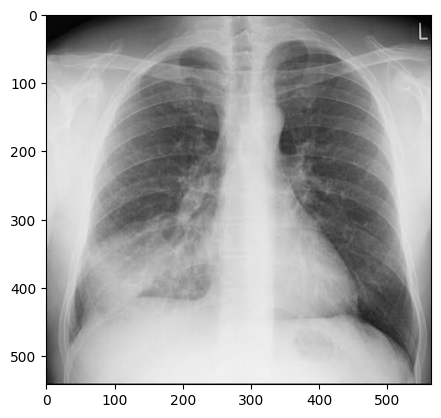

(542, 565, 3)
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 995ms/step
Prediction: PNEUMONIA (73.7% confidence)


In [30]:
import cv2
import matplotlib.pyplot as plt

test_img = cv2.imread('/content/x-rayp.jpg')

test_img = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)
plt.imshow(test_img)
plt.show()
print(test_img.shape)

test_img = cv2.resize(test_img, (256, 256))
test_input = test_img.reshape(1, 256, 256, 3) / 255.0

prediction = model.predict(test_input)
prob = prediction[0][0]
label = 'PNEUMONIA' if prob > 0.5 else 'NORMAL'
confidence = prob if prob > 0.5 else 1 - prob
print(f"Prediction: {label} ({confidence*100:.1f}% confidence)")